# 0c_referencia_terraclass — referência de 2008 e 2010 na grade da área de estudo

Leva o TerraClass 2008 e 2010 (cerca de 10 m, EPSG:4674) para a grade da área de estudo (30 m, EPSG:31981, a mesma das seis imagens) e prepara o que a avaliação vai usar.

| Seção | O que faz |
|---|---|
| 1. Grade e leitura | Lê a grade da área de estudo e só a janela do TerraClass que a cobre; converte para a nova legenda (a mesma tabela do 0a) |
| 2. Reamostragem | Calcula, para cada pixel de 30 m, a fração de cada classe do TerraClass dentro dele; a classe é a majoritária (moda) e a **pureza** é a fração dela |
| 3. Distância à borda | Mesma definição do 0b: 1 = outro rótulo na janela 3 × 3, …, 5 = nenhum na 9 × 9 |
| 4. Transições 2008 → 2010 | Tabela de mudanças e pixels com a transição proibida  |
| 5. Amostras da dissertação | Concordância entre o TerraClass e as amostras de 2008 e 2010 da dissertação, na legenda de 4 classes |
| 6. Figuras e saídas | Mapas, pureza, bordas e lista de arquivos |

Lê `dados\terraclass\`, `resultados\0a_aquisicao\legenda_terraclass.csv`, a grade de `landsat_2010.tif` e as amostras da dissertação. Grava só em `resultados\0c_referencia_terraclass\`.

Códigos: F = 1, VS = 2, PA = 3, AG = 4; 9 = fora da legenda; 0 = sem dado.


Obs.: Documentação do Código feita com auxílio de IA (Claude Opus 5.5)

## Parâmetros

In [1]:
# ============================== PARÂMETROS ==============================
PASTA_PROJETO    = r"C:\cmap_ftl\terraclass"
PASTA_TERRACLASS = rf"{PASTA_PROJETO}\dados\terraclass"
PASTA_0A         = rf"{PASTA_PROJETO}\resultados\0a_aquisicao"           # legenda_terraclass.csv
PASTA_SAIDA      = rf"{PASTA_PROJETO}\resultados\0c_referencia_terraclass"
# Somente leitura (projeto atual)
ARQ_GRADE        = r"C:\cmap_ftl\dados_preparados\imagens\landsat_2010.tif"   # define a grade de saída
PASTA_AMOSTRAS_DISSERTACAO = r"C:\cmap_ftl\dados_preparados\amostras"
ARQ_LEGENDA_DISSERTACAO    = r"C:\cmap_ftl\dados_preparados\legenda.json"

ANOS = [2008, 2010]
CLASSES = {1: "F", 2: "VS", 3: "PA", 4: "AG"}
CODIGO_FORA, CODIGO_SEM_DADO = 9, 0
MARGEM_GRAUS = 0.01          # folga da janela lida do TerraClass em volta da área de estudo (~1 km)

COMPARAR_DISSERTACAO = False
# o Solo Exposto da dissertação é o solo de áreas agrícolas, que o TerraClass inclui em Cultura Agrícola Temporária.
DISSERTACAO_PARA_NOVA = {"AG": "AG", "SE": "AG", "F": "F", "VS1": "VS", "VSD": "VS", "PA": "PA"}

In [2]:
import os, json, glob
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import array_bounds
from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.windows import from_bounds
from scipy import ndimage
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

if not os.path.abspath(PASTA_SAIDA).lower().startswith(os.path.abspath(PASTA_PROJETO).lower() + os.sep):
    raise ValueError(f"PASTA_SAIDA precisa ficar dentro de {PASTA_PROJETO}")
os.makedirs(PASTA_SAIDA, exist_ok=True)
NOMES = {**CLASSES, CODIGO_FORA: "fora", CODIGO_SEM_DADO: "sem dado"}
CATEGORIAS = list(CLASSES) + [CODIGO_FORA, CODIGO_SEM_DADO]
COD_F = [c for c, s in CLASSES.items() if s == "F"][0]

## 1. Grade da área de estudo e leitura do TerraClass

A grade de saída é a de `landsat_2010.tif` (750 colunas × 1.200 linhas de 30 m). Do TerraClass do Pará, lê-se só a janela que cobre a área de estudo com uma folga de `MARGEM_GRAUS`. Os códigos originais são convertidos para a nova legenda com a mesma tabela usada no 0a (`legenda_terraclass.csv`), ainda na resolução original.

In [3]:
with rasterio.open(ARQ_GRADE) as src:
    T, CRS_GRADE, H, W = src.transform, src.crs, src.height, src.width
limites = array_bounds(H, W, T)       # (oeste, sul, leste, norte) na grade
print(f"Grade: {W} colunas x {H} linhas | pixel {T.a:.0f} m | {CRS_GRADE} | limites {tuple(round(v) for v in limites)}")

legenda = pd.read_csv(os.path.join(PASTA_0A, "legenda_terraclass.csv"))
tc10, bruto10, transf10, crs_tc = {}, {}, {}, None
for ano in ANOS:
    tifs = glob.glob(os.path.join(PASTA_TERRACLASS, f"*{ano}*.tif"))
    if len(tifs) != 1:
        raise ValueError(f"{ano}: esperava 1 GeoTIFF do TerraClass com o ano no nome; achei {tifs}")
    with rasterio.open(tifs[0]) as src:
        oeste, sul, leste, norte = transform_bounds(CRS_GRADE, src.crs, *limites, densify_pts=21)
        janela = from_bounds(oeste - MARGEM_GRAUS, sul - MARGEM_GRAUS, leste + MARGEM_GRAUS, norte + MARGEM_GRAUS,
                             transform=src.transform).round_offsets().round_lengths()
        valor_sem_dado = int(src.nodata) if src.nodata is not None else 0
        bruto = src.read(1, window=janela, boundless=True, fill_value=valor_sem_dado)
        transf10[ano], crs_tc = src.window_transform(janela), src.crs
        res_tc = src.res
    tabela_ano = legenda[legenda["ano"] == ano]
    lut = np.full(256, CODIGO_FORA, dtype=np.uint8)              # valor sem nome no .qml -> fora
    lut[tabela_ano["valor"].to_numpy()] = tabela_ano["codigo_novo"].to_numpy()
    lut[valor_sem_dado] = CODIGO_SEM_DADO
    tc10[ano] = lut[bruto]
    bruto10[ano] = bruto
    cont = {NOMES[c]: int((tc10[ano] == c).sum()) for c in CATEGORIAS}
    print(f"{ano}: {os.path.basename(tifs[0])} | janela {bruto.shape[1]} x {bruto.shape[0]} px de {res_tc[0]:.5f}° | pixels: {cont}")

Grade: 750 colunas x 1200 linhas | pixel 30 m | EPSG:31981 | limites (717855, 9637075, 740355, 9673075)
2008: AMZ.2008.PARA.15.M.tif | janela 2478 x 3843 px de 0.00009° | pixels: {'F': 6918014, 'VS': 869964, 'PA': 1174854, 'AG': 279970, 'fora': 280152, 'sem dado': 0}
2010: AMZ.2010.PARA.15.M.tif | janela 2478 x 3843 px de 0.00009° | pixels: {'F': 6867445, 'VS': 975473, 'PA': 1407749, 'AG': 243417, 'fora': 28870, 'sem dado': 0}


## 2. Reamostragem para 30 m: classe majoritária e pureza

Cada pixel de 30 m cobre cerca de 9 pixels do TerraClass. Para cada categoria (F, VS, PA, AG, fora e sem dado), a máscara binária a 10 m é reprojetada para a grade de 30 m pela **média**, o que dá a fração da categoria dentro do pixel. A classe de referência é a de maior fração (moda) e a **pureza** é essa fração. A pureza mede quanto o pixel de 30 m é misto segundo o próprio TerraClass e serve para a análise de sensibilidade da avaliação.

Observação de método: no treino, o GEE leva o TerraClass à grade das cenas pelas pirâmides por moda seguidas de vizinho mais próximo. A diferença entre os dois procedimentos fica nos pixels mistos.

In [4]:
perfil = {"driver": "GTiff", "height": H, "width": W, "count": 1, "crs": CRS_GRADE, "transform": T, "compress": "lzw"}
ref, pureza = {}, {}
for ano in ANOS:
    fracoes = np.zeros((len(CATEGORIAS), H, W), dtype=np.float32)
    for k, cat in enumerate(CATEGORIAS):
        reproject(source=(tc10[ano] == cat).astype(np.float32), destination=fracoes[k],
                  src_transform=transf10[ano], src_crs=crs_tc, dst_transform=T, dst_crs=CRS_GRADE,
                  resampling=Resampling.average)
    soma = fracoes.sum(axis=0)
    print(f"{ano}: soma das frações por pixel entre {soma.min():.3f} e {soma.max():.3f} (deve ser ~1)")
    ref[ano] = np.array(CATEGORIAS, dtype=np.uint8)[fracoes.argmax(axis=0)]
    pureza[ano] = fracoes.max(axis=0) / np.maximum(soma, 1e-6)
    with rasterio.open(os.path.join(PASTA_SAIDA, f"referencia_{ano}.tif"), "w", dtype="uint8", nodata=CODIGO_SEM_DADO, **perfil) as dst:
        dst.write(ref[ano], 1)
    with rasterio.open(os.path.join(PASTA_SAIDA, f"pureza_{ano}.tif"), "w", dtype="uint8", nodata=None, **perfil) as dst:
        dst.write(np.round(pureza[ano] * 100).astype(np.uint8), 1)

# o que há dentro de "fora da legenda": classe original majoritária (moda) nesses pixels
nome_original = dict(zip(legenda["valor"], legenda["rotulo"]))
for ano in ANOS:
    moda = np.zeros((H, W), dtype=np.uint8)
    reproject(source=bruto10[ano], destination=moda, src_transform=transf10[ano], src_crs=crs_tc,
              dst_transform=T, dst_crs=CRS_GRADE, resampling=Resampling.mode)
    valores, contagens = np.unique(moda[ref[ano] == CODIGO_FORA], return_counts=True)
    print(f"{ano}: pixels fora da legenda por classe original:",
          {nome_original.get(int(v), f"valor {int(v)}"): int(c) for v, c in zip(valores, contagens)})

2008: soma das frações por pixel entre 1.000 e 1.000 (deve ser ~1)
2010: soma das frações por pixel entre 1.000 e 1.000 (deve ser ~1)
2008: pixels fora da legenda por classe original: {'VEGETACAO NATURAL FLORESTAL SECUNDARIA': 1, 'URBANIZADA': 594, 'OUTROS USOS': 76, 'DESFLORESTAMENTO NO ANO': 3017, 'CORPO DAGUA': 896, 'NAO OBSERVADO': 20152}
2010: pixels fora da legenda por classe original: {'VEGETACAO NATURAL FLORESTAL SECUNDARIA': 2, 'PASTAGEM ARBUSTIVA/ARBOREA': 13, 'URBANIZADA': 594, 'OUTROS USOS': 33, 'DESFLORESTAMENTO NO ANO': 1331, 'CORPO DAGUA': 896, 'NAO OBSERVADO': 128}


## 3. Distância à borda

Mesma definição do 0b, agora sobre a referência de 30 m: distância, em pixels (métrica de tabuleiro), até o pixel mais próximo com outro rótulo (outra classe, fora da legenda ou sem dado). 1 = pixel de borda; 5 = nenhum outro rótulo na janela 9 × 9. Nas margens da grade, a janela é completada repetindo o pixel da margem, para não criar bordas falsas.

In [5]:
dist = {}
linhas = []
for ano in ANOS:
    d = np.full((H, W), 5, dtype=np.uint8)
    for r in range(4, 0, -1):
        tamanho = 2 * r + 1
        minimo = ndimage.minimum_filter(ref[ano], size=tamanho, mode="nearest")
        maximo = ndimage.maximum_filter(ref[ano], size=tamanho, mode="nearest")
        d[minimo != maximo] = r
    dist[ano] = d
    with rasterio.open(os.path.join(PASTA_SAIDA, f"dist_borda_{ano}.tif"), "w", dtype="uint8", nodata=None, **perfil) as dst:
        dst.write(d, 1)
    for cat in CATEGORIAS:
        m = ref[ano] == cat
        n = int(m.sum())
        linhas.append({"ano": ano, "classe": NOMES[cat], "pixels": n, "area_km2": round(n * abs(T.a * T.e) / 1e6, 2),
                       "fracao_grade_pct": round(100 * n / (H * W), 2),
                       "pureza_media_pct": round(100 * float(pureza[ano][m].mean()), 1) if n else np.nan,
                       "pixels_mistos_pct": round(100 * float((pureza[ano][m] < 0.999).mean()), 1) if n else np.nan,
                       "borda_3x3_pct": round(100 * float((d[m] == 1).mean()), 1) if n else np.nan,
                       "borda_5x5_pct": round(100 * float((d[m] <= 2).mean()), 1) if n else np.nan})
resumo = pd.DataFrame(linhas)
resumo.to_csv(os.path.join(PASTA_SAIDA, "resumo_referencia.csv"), index=False)
print(resumo.to_string(index=False))
na_legenda = {ano: np.isin(ref[ano], list(CLASSES)) for ano in ANOS}
for ano in ANOS:
    print(f"\n{ano}: pixels na legenda {100 * na_legenda[ano].mean():.1f}% da grade | "
          f"de borda entre eles {100 * (dist[ano][na_legenda[ano]] == 1).mean():.1f}%")

 ano   classe  pixels  area_km2  fracao_grade_pct  pureza_media_pct  pixels_mistos_pct  borda_3x3_pct  borda_5x5_pct
2008        F  639107    575.20             71.01              99.4                2.3            4.5            8.5
2008       VS   87013     78.31              9.67              94.3               25.9           45.5           69.4
2008       PA  118462    106.62             13.16              96.7               15.7           28.0           47.2
2008       AG   30682     27.61              3.41              98.1                8.6           16.9           31.4
2008     fora   24736     22.26              2.75              95.0               23.3           40.3           62.7
2008 sem dado       0      0.00              0.00               NaN                NaN            NaN            NaN
2010        F  634497    571.05             70.50              99.4                2.4            4.6            8.7
2010       VS   95939     86.35             10.66              9

## 4. Transições 2008 p/ 2010

A tabela cruza a referência dos dois anos em todos os pixels da grade. Pela matriz de transição do projeto, só é proibido voltar a ser Floresta; pixels que são F em 2010 e eram VS, PA ou AG em 2008 indicam erro de um dos dois mapas e ficam marcados em `incoerencia_2008_2010.tif` (1). Pixels F em 2010 que eram fora da legenda ou sem dado em 2008 recebem 2.

In [6]:
a0, a1 = ANOS[0], ANOS[-1]
trans = pd.crosstab(pd.Series(ref[a0].ravel(), name=f"{a0}").map(NOMES), pd.Series(ref[a1].ravel(), name=f"{a1}").map(NOMES))
ordem = [NOMES[c] for c in CATEGORIAS]
trans = trans.reindex(index=ordem, columns=ordem, fill_value=0)
trans.to_csv(os.path.join(PASTA_SAIDA, f"transicoes_{a0}_{a1}.csv"))
print(f"Pixels por classe em {a0} (linhas) e {a1} (colunas):\n", trans.to_string())

ambos = na_legenda[a0] & na_legenda[a1]
mudou = ambos & (ref[a0] != ref[a1])
proibida = (ref[a1] == COD_F) & np.isin(ref[a0], [c for c in CLASSES if c != COD_F])
outra_origem = (ref[a1] == COD_F) & np.isin(ref[a0], [CODIGO_FORA, CODIGO_SEM_DADO])
incoerencia = np.zeros((H, W), dtype=np.uint8)
incoerencia[proibida], incoerencia[outra_origem] = 1, 2
with rasterio.open(os.path.join(PASTA_SAIDA, f"incoerencia_{a0}_{a1}.tif"), "w", dtype="uint8", nodata=None, **perfil) as dst:
    dst.write(incoerencia, 1)
print(f"\nPixels na legenda nos dois anos: {int(ambos.sum())} | mudaram de classe: {int(mudou.sum())} "
      f"({100 * mudou.sum() / ambos.sum():.1f}%)")
print(f"Transição proibida (VS, PA ou AG -> F): {int(proibida.sum())} pixels | fora/sem dado -> F: {int(outra_origem.sum())}")

Pixels por classe em 2008 (linhas) e 2010 (colunas):
 2010           F     VS      PA     AG  fora  sem dado
2008                                                  
F         634437    809    1685    746  1430         0
VS            11  82515    4111    356    20         0
PA            32   5358  111297   1760    15         0
AG             0    126    7996  22560     0         0
fora          17   7131   14543   1513  1532         0
sem dado       0      0       0      0     0         0

Pixels na legenda nos dois anos: 873799 | mudaram de classe: 22990 (2.6%)
Transição proibida (VS, PA ou AG -> F): 43 pixels | fora/sem dado -> F: 17


## 5. Concordância com as amostras da dissertação

As amostras de 2008 e 2010 da dissertação (pixels das regiões amostrais) são convertidas para a legenda de 4 classes com `DISSERTACAO_PARA_NOVA` e comparadas com a referência do TerraClass nos mesmos pixels. Nenhuma das duas é a verdade: o resultado mede a **concordância entre as duas referências** na área de estudo e ajuda a interpretar a avaliação. Pixels em que o TerraClass está fora da legenda contam como discordância.

In [7]:
if COMPARAR_DISSERTACAO:
    with open(ARQ_LEGENDA_DISSERTACAO, encoding="utf-8") as arq:
        cod_dissertacao = {int(k): v for k, v in json.load(arq)["classes"].items()}
    codigo_novo = {s: c for c, s in CLASSES.items()}
    linhas_conc = []
    for ano in ANOS:
        with rasterio.open(os.path.join(PASTA_AMOSTRAS_DISSERTACAO, f"amostras_{ano}.tif")) as src:
            if src.shape != (H, W) or not src.transform.almost_equals(T):
                raise ValueError(f"amostras_{ano}.tif fora da grade da área de estudo")
            amostra = src.read(1)
        convertida = np.zeros_like(amostra)
        for c, sigla in cod_dissertacao.items():
            convertida[amostra == c] = codigo_novo[DISSERTACAO_PARA_NOVA[sigla]]
        m = convertida > 0
        d_px, t_px, borda_px = convertida[m], ref[ano][m], dist[ano][m] == 1
        matriz = pd.crosstab(pd.Series(d_px, name="dissertação").map(NOMES), pd.Series(t_px, name="TerraClass").map(NOMES))
        matriz = matriz.reindex(index=list(CLASSES.values()), columns=ordem, fill_value=0)
        matriz.to_csv(os.path.join(PASTA_SAIDA, f"concordancia_dissertacao_{ano}.csv"))
        print(f"\n{ano}: pixels amostrados {int(m.sum())} — linhas = dissertação, colunas = TerraClass")
        print(matriz.to_string())
        igual = d_px == t_px
        linha = {"ano": ano, "pixels": int(m.sum()), "concordancia_pct": round(100 * igual.mean(), 1),
                 "concordancia_borda_pct": round(100 * igual[borda_px].mean(), 1) if borda_px.any() else np.nan,
                 "concordancia_interior_pct": round(100 * igual[~borda_px].mean(), 1) if (~borda_px).any() else np.nan}
        for c, s in CLASSES.items():
            linha[f"{s}_igual_pct"] = round(100 * float(igual[d_px == c].mean()), 1) if (d_px == c).any() else np.nan
        linhas_conc.append(linha)
    concordancia = pd.DataFrame(linhas_conc)
    concordancia.to_csv(os.path.join(PASTA_SAIDA, "concordancia_dissertacao_resumo.csv"), index=False)
    print("\nResumo (X_igual_pct = % dos pixels da classe X na dissertação que o TerraClass também chama de X):")
    print(concordancia.to_string(index=False))

## 6. Figuras e saídas

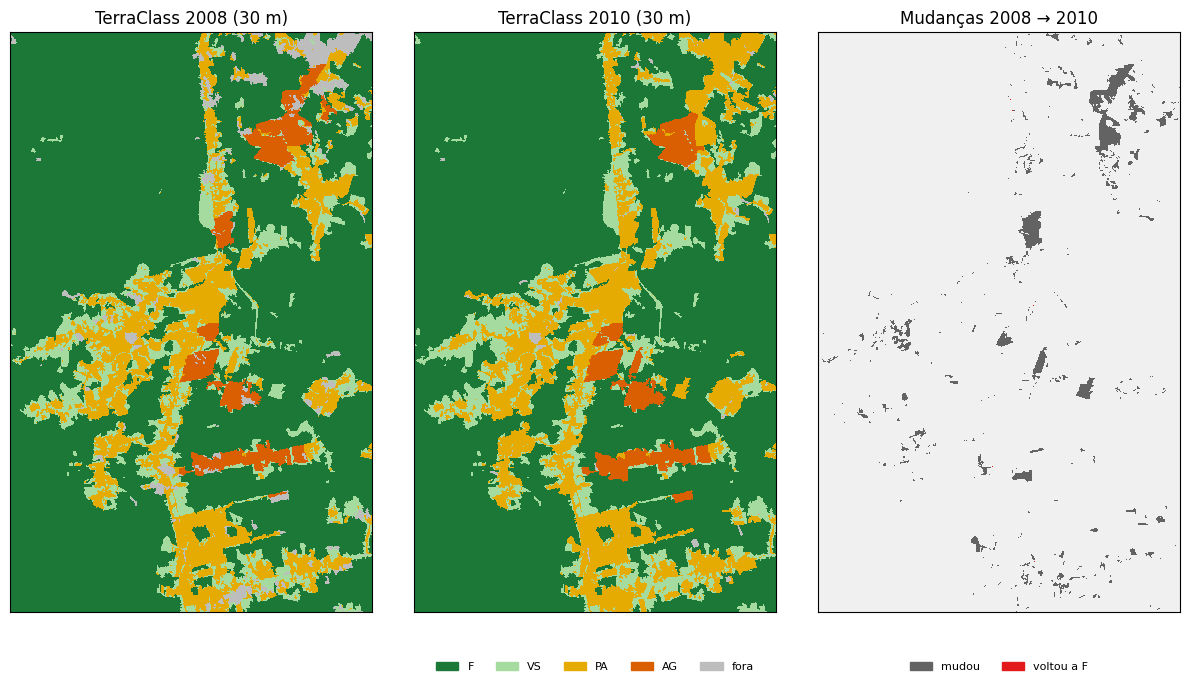

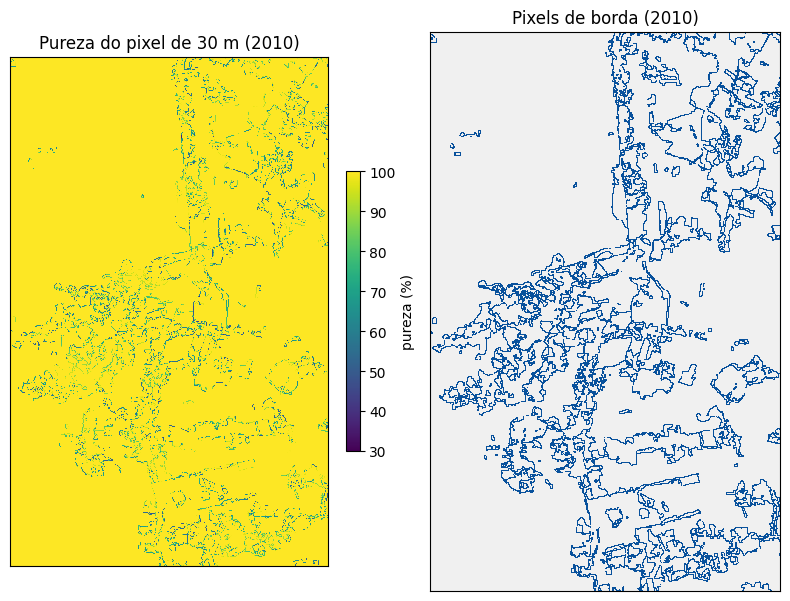

dist_borda_2008.tif                          0.09 MB
dist_borda_2010.tif                          0.09 MB
incoerencia_2008_2010.tif                    0.02 MB
mapas_referencia.png                         0.14 MB
pureza_2008.tif                              0.11 MB
pureza_2010.tif                              0.10 MB
pureza_borda.png                             0.30 MB
referencia_2008.tif                          0.06 MB
referencia_2010.tif                          0.05 MB
resumo_referencia.csv                        0.00 MB
transicoes_2008_2010.csv                     0.00 MB


In [8]:
CORES = {1: "#1b7837", 2: "#a6dba0", 3: "#e6ab02", 4: "#d95f02", CODIGO_FORA: "#bdbdbd", CODIGO_SEM_DADO: "#ffffff"}
indice = np.zeros(256, dtype=np.uint8)
for k, cat in enumerate(CATEGORIAS):
    indice[cat] = k
cmap = ListedColormap([CORES[c] for c in CATEGORIAS])

fig, eixos = plt.subplots(1, 3, figsize=(12, 6.5))
for ax, ano in zip(eixos[:2], ANOS):
    ax.imshow(indice[ref[ano]], cmap=cmap, vmin=-0.5, vmax=len(CATEGORIAS) - 0.5, interpolation="nearest")
    ax.set_title(f"TerraClass {ano} (30 m)")
mapa_mud = np.where(mudou, 1, 0) + np.where(incoerencia == 1, 1, 0)
eixos[2].imshow(mapa_mud, cmap=ListedColormap(["#f0f0f0", "#636363", "#e31a1c"]), vmin=-0.5, vmax=2.5, interpolation="nearest")
eixos[2].set_title(f"Mudanças {a0} → {a1}")
for ax in eixos:
    ax.set_xticks([]); ax.set_yticks([])
eixos[1].legend(handles=[Patch(color=CORES[c], label=NOMES[c]) for c in CATEGORIAS if c != CODIGO_SEM_DADO],
                loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=5, fontsize=8, frameon=False)
eixos[2].legend(handles=[Patch(color="#636363", label="mudou"), Patch(color="#e31a1c", label="voltou a F")],
                loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(PASTA_SAIDA, "mapas_referencia.png"), dpi=200, bbox_inches="tight")
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(8, 6.5))
im = eixos[0].imshow(pureza[a1] * 100, cmap="viridis", vmin=30, vmax=100, interpolation="nearest")
fig.colorbar(im, ax=eixos[0], fraction=0.04, label="pureza (%)")
eixos[0].set_title(f"Pureza do pixel de 30 m ({a1})")
eixos[1].imshow(dist[a1] == 1, cmap=ListedColormap(["#f0f0f0", "#08519c"]), interpolation="nearest")
eixos[1].set_title(f"Pixels de borda ({a1})")
for ax in eixos:
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
fig.savefig(os.path.join(PASTA_SAIDA, "pureza_borda.png"), dpi=200, bbox_inches="tight")
plt.show()

for nome in sorted(os.listdir(PASTA_SAIDA)):
    print(f"{nome:40s} {os.path.getsize(os.path.join(PASTA_SAIDA, nome)) / 1e6:8.2f} MB")

## Saídas

| Arquivo | Conteúdo |
|---|---|
| `referencia_AAAA.tif` | Classe do TerraClass na grade da área de estudo (1–4; 9 = fora da legenda; 0 = sem dado) |
| `pureza_AAAA.tif` | Fração (%) da classe majoritária dentro do pixel de 30 m |
| `dist_borda_AAAA.tif` | Distância à borda (1 = pixel de borda; 5 = nenhum outro rótulo na janela 9 × 9) |
| `incoerencia_2008_2010.tif` | 1 = VS, PA ou AG em 2008 e F em 2010; 2 = fora/sem dado em 2008 e F em 2010 |
| `resumo_referencia.csv` | Área, pureza e bordas por classe e ano |
| `transicoes_2008_2010.csv` | Tabela cruzada 2008 × 2010 |
| `concordancia_dissertacao_*.csv` | Concordância com as amostras da dissertação |
| `mapas_referencia.png`, `pureza_borda.png` | Figuras |